In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

import matplotlib.pyplot as plt
import os

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


In [3]:
# Normalisation values for CIFAR-10
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

# Convert images to tensors and normalise them
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Load training dataset
train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Load test dataset
test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training dataset size:", len(train_dataset))
print("Test dataset size:", len(test_dataset))

Training dataset size: 50000
Test dataset size: 10000


In [4]:
# Use the same random seed as Exercise 1
generator = torch.Generator().manual_seed(42)

train_split, val_split = random_split(
    train_dataset,
    [45000, 5000],
    generator=generator
)

# Same batch size as Exercise 1
batch_size = 64

train_loader = DataLoader(
    train_split,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_split,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Training images:", len(train_split))
print("Validation images:", len(val_split))
print("Testing images:", len(test_dataset))

Training images: 45000
Validation images: 5000
Testing images: 10000


In [5]:
class CNN(nn.Module):

    def __init__(self):
        super(CNN, self).__init__()

        self.conv_layers = nn.Sequential(

            # Trainable Layer 1
            nn.Conv2d(
                in_channels=3,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),

            # Trainable Layer 2
            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),

            # Pooling
            nn.MaxPool2d(kernel_size=2),

            # Second pooling operation
            nn.MaxPool2d(kernel_size=2)
        )

        # Trainable Layer 3
        self.fc = nn.Linear(64 * 8 * 8, 10)

    def forward(self, x):

        # Extract image features
        x = self.conv_layers(x)

        # Flatten feature maps
        x = torch.flatten(x, start_dim=1)

        # Classify into 10 classes
        x = self.fc(x)

        return x

In [6]:
model = CNN().to(device)

print(model)

CNN(
  (conv_layers): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc): Linear(in_features=4096, out_features=10, bias=True)
)


In [7]:
total_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Total trainable parameters:", total_parameters)

Total trainable parameters: 60362


In [8]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [9]:
def train_one_epoch(model, train_loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Make predictions
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Clear old gradients
        optimizer.zero_grad()

        # Calculate gradients
        loss.backward()

        # Update model weights
        optimizer.step()

        # Calculate total loss
        running_loss += loss.item() * images.size(0)

        # Calculate accuracy
        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [10]:
def evaluate(model, data_loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in data_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs.data, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [11]:
num_epochs = 10

history_cnn = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
    "test_accuracy": []
}

for epoch in range(num_epochs):

    # Train
    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    # Validate
    val_loss, val_accuracy = evaluate(
        model,
        val_loader,
        criterion,
        device
    )

    # Test
    test_loss, test_accuracy = evaluate(
        model,
        test_loader,
        criterion,
        device
    )

    # Save results
    history_cnn["train_loss"].append(train_loss)
    history_cnn["val_loss"].append(val_loss)
    history_cnn["train_accuracy"].append(train_accuracy)
    history_cnn["val_accuracy"].append(val_accuracy)
    history_cnn["test_accuracy"].append(test_accuracy)

    print(f"\nEpoch [{epoch+1}/{num_epochs}]")
    print(f"Training Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Training Accuracy: {train_accuracy:.2f}%")
    print(f"Validation Accuracy: {val_accuracy:.2f}%")
    print(f"Test Accuracy: {test_accuracy:.2f}%")


Epoch [1/10]
Training Loss: 1.2801
Validation Loss: 1.0341
Training Accuracy: 55.13%
Validation Accuracy: 63.96%
Test Accuracy: 64.75%

Epoch [2/10]
Training Loss: 0.9329
Validation Loss: 0.9448
Training Accuracy: 67.88%
Validation Accuracy: 67.46%
Test Accuracy: 67.74%

Epoch [3/10]
Training Loss: 0.8198
Validation Loss: 0.8836
Training Accuracy: 71.69%
Validation Accuracy: 70.04%
Test Accuracy: 69.55%

Epoch [4/10]
Training Loss: 0.7392
Validation Loss: 0.8939
Training Accuracy: 74.70%
Validation Accuracy: 68.66%
Test Accuracy: 69.42%

Epoch [5/10]
Training Loss: 0.6725
Validation Loss: 0.8739
Training Accuracy: 76.90%
Validation Accuracy: 70.10%
Test Accuracy: 70.14%

Epoch [6/10]
Training Loss: 0.6209
Validation Loss: 0.8858
Training Accuracy: 78.61%
Validation Accuracy: 70.08%
Test Accuracy: 70.31%

Epoch [7/10]
Training Loss: 0.5733
Validation Loss: 0.8880
Training Accuracy: 80.28%
Validation Accuracy: 70.62%
Test Accuracy: 70.12%

Epoch [8/10]
Training Loss: 0.5327
Validation L

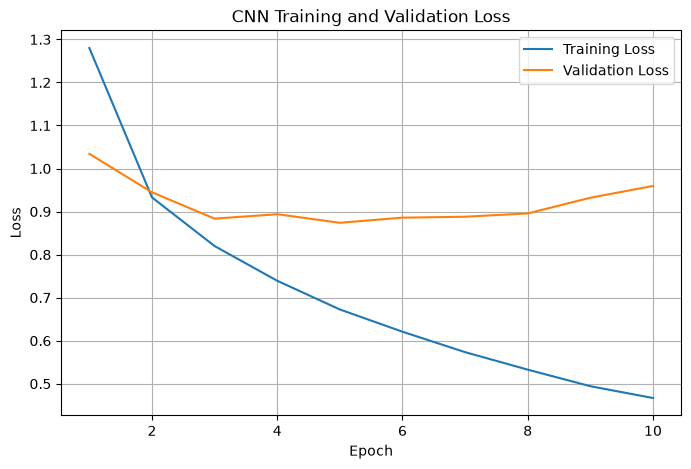

In [12]:
os.makedirs("outputs", exist_ok=True)

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history_cnn["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs,
    history_cnn["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.savefig(
    "outputs/cnn_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

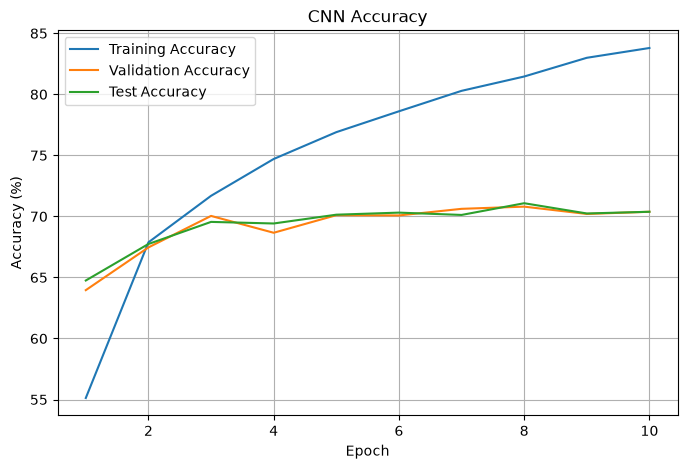

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history_cnn["train_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    epochs,
    history_cnn["val_accuracy"],
    label="Validation Accuracy"
)

plt.plot(
    epochs,
    history_cnn["test_accuracy"],
    label="Test Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("CNN Accuracy")

plt.legend()
plt.grid(True)

plt.savefig(
    "outputs/cnn_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
print("FINAL CNN RESULTS")
print("-------------------------")

print(f"Training Loss: {history_cnn['train_loss'][-1]:.4f}")
print(f"Validation Loss: {history_cnn['val_loss'][-1]:.4f}")

print(f"Training Accuracy: {history_cnn['train_accuracy'][-1]:.2f}%")
print(f"Validation Accuracy: {history_cnn['val_accuracy'][-1]:.2f}%")
print(f"Test Accuracy: {history_cnn['test_accuracy'][-1]:.2f}%")

print(f"Trainable Parameters: {total_parameters:,}")

FINAL CNN RESULTS
-------------------------
Training Loss: 0.4668
Validation Loss: 0.9595
Training Accuracy: 83.79%
Validation Accuracy: 70.38%
Test Accuracy: 70.38%
Trainable Parameters: 60,362


In [16]:
print("MLP vs CNN COMPARISON")
print("-----------------------------")

print("CNN Train Accuracy:",
      f"{history_cnn['train_accuracy'][-1]:.2f}%")

print("CNN Validation Accuracy:",
      f"{history_cnn['val_accuracy'][-1]:.2f}%")

print("CNN Test Accuracy:",
      f"{history_cnn['test_accuracy'][-1]:.2f}%")

print("CNN Parameters:",
      f"{total_parameters:,}")

print("CNN Training Loss:", history_cnn["train_loss"][-1])
print("CNN Validation Loss:", history_cnn["val_loss"][-1])

MLP vs CNN COMPARISON
-----------------------------
CNN Train Accuracy: 83.79%
CNN Validation Accuracy: 70.38%
CNN Test Accuracy: 70.38%
CNN Parameters: 60,362
CNN Training Loss: 0.4668495841662089
CNN Validation Loss: 0.9594705455780029


### Exercise 2 – CNN Classifier: Results, Comparison and Discussion

The CNN classifier was implemented using two convolutional layers and one fully connected layer, resulting in three trainable layers. ReLU activation functions and MaxPool2d operations were used to extract image features and reduce the spatial dimensions of feature maps.

Both the MLP and CNN were trained using the CIFAR-10 dataset with the same training, validation and test splits. The models also used the same batch size of 64, Adam optimizer, learning rate of 0.001 and 10 training epochs to support a fair comparison.

The MLP achieved a training accuracy of 67.88%, validation accuracy of 51.16% and test accuracy of 52.71%. In comparison, the CNN achieved a training accuracy of 83.79%, validation accuracy of 70.38% and test accuracy of 70.38%.

The CNN improved validation accuracy by 19.22 percentage points compared with the MLP. It also achieved lower training loss (0.4668) and validation loss (0.9595), compared with the MLP's training loss of 0.9005 and validation loss of 1.5575.

A significant difference was also observed in the number of trainable parameters. The MLP contained 1,707,274 trainable parameters, whereas the CNN contained only 60,362. This means that the CNN used approximately 96.46% fewer trainable parameters than the MLP while achieving better classification performance.

The difference in performance can be explained by how the two architectures process images. The MLP flattens each image into a one-dimensional vector, which removes its original spatial structure and makes it more difficult to recognise relationships between neighbouring pixels.

In contrast, CNNs use convolutional filters to learn local visual features such as edges, textures and shapes. These filters scan different regions of an image while preserving spatial relationships between nearby pixels. The same filters can also be reused across different image locations, reducing the number of parameters required. Max pooling further reduces feature-map dimensions while retaining useful information.

Both models showed signs of overfitting because their training accuracies were higher than their validation accuracies. However, the CNN achieved a smaller training-validation accuracy gap and substantially better validation performance than the MLP.

Overall, the results demonstrate that the CNN was more effective than the MLP for CIFAR-10 image classification. It achieved higher classification accuracy, lower training and validation losses, and a significantly smaller number of trainable parameters. This supports the suitability of convolutional neural networks for image classification tasks because they can learn spatial and visual features more effectively.